# 8.4 Statistical Learning Concepts

**Goal:** relate generalization and regularization to learning curves and the uncertainty of predictions.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Data Preprocessing](1_Data-Preprocessing.ipynb)
2. [Feature Engineering](2_Feature-Engineering.ipynb)
3. [Model Evaluation Statistics](3_Model-Evaluation-Statistics.ipynb)
4. [Statistical Learning Concepts](4_Statistical-Learning-Concepts.ipynb)
5. [Advanced ML Statistics](5_Advanced-ML-Statistics.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Bias-Variance Tradeoff

Under squared loss and a model $Y=f(x)+\epsilon$ with E[ε|x]=0, expected prediction error at x can decompose into noise variance, squared bias of the fitted prediction over repeated training samples, and its variance. This is a repeated-training statement conditional on assumptions, not an explanation recoverable from one training score alone.

A flexible model can reduce approximation bias and increase sensitivity to training data, but modern settings can have more complex behavior than a universally U-shaped curve. “More complex always overfits” is not a theorem. The relevant loss, training algorithm, regularization, and sample size determine the pattern.

## 2. Overfitting, Underfitting, and Generalization

**Underfitting** misses relevant patterns even on training data; **overfitting** adapts to training noise or idiosyncrasies and harms new-data performance. Generalization refers to the intended deployment distribution, not any arbitrary held-out rows. Leakage can create apparently excellent train and validation scores without genuine usefulness.

**Regularization** constrains the fitted solution using penalties, early stopping, architecture choices, data augmentation, or other prior structure. **Model complexity** is not just parameter count; effective capacity depends on constraints and algorithm. Tune complexity on validation data, retaining an untouched test or nested evaluation for final reporting.

In [2]:
x=np.linspace(-1,1,45);y=np.sin(3*x)+rng.normal(0,.15,len(x))
train=np.arange(0,45,2);valid=np.arange(1,45,2)
results=[]
for degree in [1,3,7,15]:
    # NumPy Polynomial.fit rescales the input domain for numerical conditioning.
    fit=np.polynomial.Polynomial.fit(x[train],y[train],degree)
    tr=np.mean((fit(x[train])-y[train])**2);va=np.mean((fit(x[valid])-y[valid])**2)
    results.append((degree,tr,va))
print("Degree, training MSE, validation MSE:",results)

Degree, training MSE, validation MSE: [(1, np.float64(0.16566450160066443), np.float64(0.22606267947743472)), (3, np.float64(0.012657038098171048), np.float64(0.03886748490176045)), (7, np.float64(0.008646837614796088), np.float64(0.02856083252816852)), (15, np.float64(0.0021316561430681545), np.float64(0.10595533828849732))]


## 3. Learning Curves

Learning curves show training/validation performance as training size or optimization effort changes. Curves by sample size help diagnose data limitation versus approximation limitations; curves by epochs show optimization/early-stopping behavior and answer another question. Average across suitable splits or repetitions to see variability; one split's wiggles are not universal trends.

A large persistent train-validation gap can indicate variance, shift, or leakage in either direction. High error on both can reflect underfitting, noisy labels, a mismatched metric, or irreducible variation. A curve suggests investigations rather than uniquely diagnosing the cause.

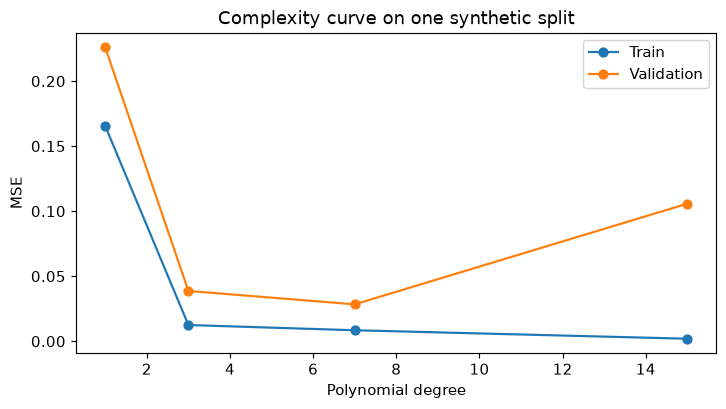

In [3]:
fig,ax=plt.subplots()
ax.plot([r[0] for r in results],[r[1] for r in results],marker="o",label="Train")
ax.plot([r[0] for r in results],[r[2] for r in results],marker="o",label="Validation")
ax.set(title="Complexity curve on one synthetic split",xlabel="Polynomial degree",ylabel="MSE");ax.legend()
fig.tight_layout();plt.show()

## 4. Prediction Intervals and Model Uncertainty

A confidence/credible interval for a mean or parameter is not a **prediction interval** for a new observation. For classical normal linear regression at design vector x₀, mean-response variance is σ²x₀ᵀ(XᵀX)⁻¹x₀; new-observation variance adds σ². A t interval uses estimated variance and n−p df under the full normal model. Extrapolation can increase parameter uncertainty and model misspecification beyond what the formula captures.

Outcome noise (often called aleatoric uncertainty) differs from limited-model/parameter information (often called epistemic). These labels depend on the model and are not uniquely identifiable from arbitrary data. Model ensembles can reflect some training variability yet share systematic bias. Under distribution shift, nominal intervals can fail even when they worked on validation data.

In [4]:
X=np.column_stack([np.ones(len(train)),x[train]]);yt=y[train]
beta=np.linalg.lstsq(X,yt,rcond=None)[0];res=yt-X@beta
s2=res@res/(len(yt)-2);x0=np.array([1.,.2]);leverage=x0@np.linalg.solve(X.T@X,x0)
tcrit=stats.t.ppf(.975,len(yt)-2);mean=x0@beta
mean_interval=mean+np.array([-1,1])*tcrit*np.sqrt(s2*leverage)
pred_interval=mean+np.array([-1,1])*tcrit*np.sqrt(s2*(1+leverage))
print("Working-linear-model mean interval:",mean_interval)
print("Working-linear-model prediction interval:",pred_interval)
print("The true mean is nonlinear here, so exact linear-model coverage is not claimed.")
assert np.ptp(pred_interval)>np.ptp(mean_interval)

Working-linear-model mean interval: [-0.04253267  0.3466731 ]
Working-linear-model prediction interval: [-0.75488614  1.05902657]
The true mean is nonlinear here, so exact linear-model coverage is not claimed.


## AI/ML application and interpretation

For training, validation, testing, and model selection, evaluate the entire pipeline under the intended deployment split. Treat curves and intervals as conditional on data quality and design. Reporting interval width without calibration/coverage checks can conceal an overconfident model.

## Practice

1. Does a very low training error demonstrate good generalization?
2. Is every train-validation gap caused solely by excessive model complexity?
3. Why is a prediction interval wider than a mean-response interval under the same classical model?
4. Can regularization repair a feature that leaks the outcome?

## Solutions

1. No. Independent target-relevant evaluation is needed.
2. No. Shift, data problems, dependent splitting, and metric noise can also contribute.
3. It includes new-outcome variation in addition to estimation uncertainty.
4. No. Leakage is a data/design problem, not simply high model variance.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](5_Advanced-ML-Statistics.ipynb).